# 7. Reinforcement learning

Penicillium registers Gymnasium environments: one episode is one batch, one step is one 12-minute sample. This
notebook goes end to end:

1. the **environment**: spaces, one episode, the recipe baseline;
2. **online optimisation**: a small policy trained with the cross-entropy method on training batches, then tested
   on unseen batches against the recipe;
3. **offline RL with Minari**: record noisy recipe batches as a Minari dataset and fit a behaviour-cloning policy.

**You need:** `pip install -e ".[notebooks]"` (Gymnasium, Minari, scikit-learn). About 3 minutes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

import os
import tempfile
import warnings

import gymnasium as gym
from gymnasium.utils.env_checker import check_env

from penicillium import RamanMode, SimulationConfig, scenarios
from penicillium.envs import IndPenSimEnv

os.environ["MINARI_DATASETS_PATH"] = tempfile.mkdtemp()  # keep the datasets of this notebook out of ~/.minari
warnings.filterwarnings("ignore", module="gymnasium.utils.env_checker")  # unbounded observation space is intended
warnings.filterwarnings("ignore", message="`eval_env` is set to None")  # evaluation uses the same environment

## 1. The environment

The pH and temperature loops run as in IndPenSim; the agent adjusts the operator inputs. Here it controls two of
them, the **sugar feed** `Fs` and the **PAA feed** `Fpaa`. An action `a` in [-1, 1] sets each input to the recipe
value times `1 + 0.5 a`, so `a = 0` is exactly the recipe. The reward is the penicillin harvested during the step,
in kg; over an episode it sums to the batch yield. Observations are the online measurements a plant has.

In [2]:
ENV_KWARGS = dict(controlled=("Fs", "Fpaa"), max_relative_change=0.5)
env = gym.make("penicillium.envs:IndPenSim-v0", **ENV_KWARGS)
check_env(
    IndPenSimEnv(config=SimulationConfig(raman_mode=RamanMode.OFF, batch_length_h=4.0), **ENV_KWARGS),
    skip_render_check=True,
)  # Gymnasium's API checks, on a short batch
print("action space:", env.action_space)
print("observation: ", env.unwrapped.observation_names)

action space: Box(-1.0, 1.0, (2,), float32)
observation:  ('time_h', 'T', 'pH', 'DO2', 'O2', 'CO2outgas', 'OUR', 'CER', 'V', 'Wt', 'Fa', 'Fb', 'Fc', 'Fh')


In [3]:
def run_episode(env, policy, seed):
    """Play one batch with ``policy(obs) -> action``; return the yield [kg] and the batch's channels."""
    obs, _ = env.reset(seed=seed)
    total, done = 0.0, False
    while not done:
        obs, reward, terminated, truncated, _ = env.step(policy(obs))
        total += reward
        done = terminated or truncated
    return total, env.unwrapped.sim.result().to_pandas(["Fs", "Fpaa", "PAA", "P"])


recipe = lambda obs: np.zeros(2, np.float32)  # noqa: E731
rng = np.random.default_rng(0)
random_policy = lambda obs: rng.uniform(-1, 1, 2).astype(np.float32)  # noqa: E731

print(f"recipe:        {run_episode(env, recipe, seed=1)[0]:7.0f} kg")
print(f"random policy: {run_episode(env, random_policy, seed=1)[0]:7.0f} kg")

recipe:           1525 kg


random policy:     967 kg


## 2. Online optimisation: the cross-entropy method

A deliberately small policy: one relative adjustment of each feed per process phase, so 2 inputs × 3 phases = 6
parameters. Phases: growth (0-50 h), early production (50-120 h), late production (from 120 h).

The cross-entropy method samples parameter vectors from a Gaussian, scores each on a few **training batches** (fixed
seeds, so every candidate sees the same batches) and refits the Gaussian to the best ones. It needs no gradients and
few episodes, which suits a simulator that runs a batch in about a second.

,Fs adjustment,Fpaa adjustment
growth 0-50 h,0.30,-0.36
early production 50-120 h,0.02,-0.15
late production 120 h-,0.78,-0.12


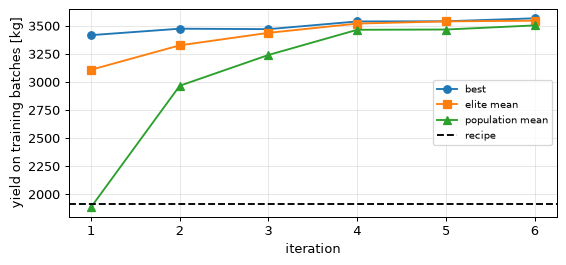

In [4]:
PHASES = [0.0, 50.0, 120.0]  # phase start times [h]


def phase_policy(theta):
    theta = np.asarray(theta, float).reshape(len(PHASES), 2)

    def policy(obs):
        phase = np.searchsorted(PHASES, obs[0], side="right") - 1  # obs[0] is the time in hours
        return np.clip(theta[phase], -1, 1).astype(np.float32)

    return policy


TRAIN_SEEDS = [11, 12]


def score(theta):
    return np.mean([run_episode(env, phase_policy(theta), seed=s)[0] for s in TRAIN_SEEDS])


cem_rng = np.random.default_rng(42)
mean, sd = np.zeros(6), np.full(6, 0.4)
history = []
for iteration in range(1, 7):
    candidates = np.clip(mean + sd * cem_rng.standard_normal((10, 6)), -1, 1)
    scores = np.array([score(c) for c in candidates])
    elite = candidates[np.argsort(scores)[-3:]]
    mean, sd = elite.mean(axis=0), elite.std(axis=0) + 0.05
    history.append(
        {
            "iteration": iteration,
            "best": scores.max(),
            "elite mean": np.sort(scores)[-3:].mean(),
            "population mean": scores.mean(),
        }
    )
theta_best = mean
baseline_train = np.mean([run_episode(env, recipe, seed=s)[0] for s in TRAIN_SEEDS])

hist = pd.DataFrame(history).set_index("iteration")
ax = hist.plot(style=["o-", "s-", "^-"], figsize=(7, 3))
ax.axhline(baseline_train, color="k", ls="--", label="recipe")
ax.set_ylabel("yield on training batches [kg]")
ax.legend(fontsize=8)
pd.DataFrame(
    np.asarray(theta_best).reshape(3, 2),
    columns=["Fs adjustment", "Fpaa adjustment"],
    index=["growth 0-50 h", "early production 50-120 h", "late production 120 h-"],
).round(2)

### Test on unseen batches

`scenarios.control_benchmark` plays each policy on the same ten test batches, with seeds never used in training.
Every policy sees the same initial states, kinetic parameters and disturbances, so the comparison is paired.

In [5]:
learned = phase_policy(theta_best)
bench_recipe = scenarios.control_benchmark(n_batches=10, seed=1000, env_kwargs=ENV_KWARGS)
bench_learned = scenarios.control_benchmark(
    policy=lambda obs, env: learned(obs), n_batches=10, seed=1000, env_kwargs=ENV_KWARGS
)
test = pd.DataFrame(
    {"recipe [kg]": bench_recipe.yield_kg.to_numpy(), "learned [kg]": bench_learned.yield_kg.to_numpy()},
    index=pd.Index(bench_recipe.batch.to_numpy(), name="test batch"),
)
test["gain [kg]"] = test["learned [kg]"] - test["recipe [kg]"]
print(
    f"mean yield: recipe {test['recipe [kg]'].mean():.0f} kg, learned {test['learned [kg]'].mean():.0f} kg; "
    f"learned policy better on {(test['gain [kg]'] > 0).sum()} of {len(test)} test batches"
)
test.round(0)

mean yield: recipe 2884 kg, learned 3858 kg; learned policy better on 10 of 10 test batches


,recipe [kg],learned [kg],gain [kg]
test batch,,,
1,3698.0,4083.0,384.0
2,3608.0,4063.0,455.0
3,3492.0,3848.0,356.0
4,2079.0,3490.0,1411.0
5,2013.0,3784.0,1771.0
6,2011.0,3573.0,1562.0
7,3557.0,4041.0,484.0
8,2593.0,3797.0,1204.0
9,2180.0,3965.0,1785.0


### Why the learned policy does better

In the model, PAA above about 2400 mg/L inhibits growth, and with the recipe's PAA feed some batches climb past that
level ([quirks](../quirks.md), 3.2). The test batch with the largest gain shows what the learned policy does
differently:

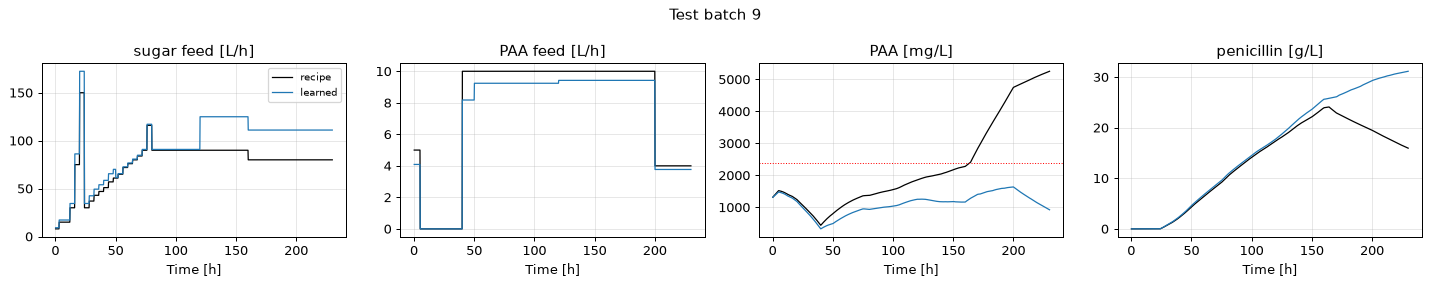

In [6]:
best = int(test["gain [kg]"].idxmax())
seed = 1000 * 100_000 + best  # the seed control_benchmark(seed=1000) gives test batch `best`
logs = {name: run_episode(env, policy, seed=seed)[1] for name, policy in (("recipe", recipe), ("learned", learned))}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharex=True)
for ax, (col, label) in zip(
    axes, [("Fs", "sugar feed [L/h]"), ("Fpaa", "PAA feed [L/h]"), ("PAA", "PAA [mg/L]"), ("P", "penicillin [g/L]")]
):
    for name, log in logs.items():
        ax.plot(log.index, log[col], lw=1, label=name, color="k" if name == "recipe" else "tab:blue")
    ax.set(title=label, xlabel="Time [h]")
axes[2].axhline(2400, color="r", lw=0.8, ls=":")
axes[0].legend(fontsize=8)
fig.suptitle(f"Test batch {best}")
fig.tight_layout()

Two caveats. The reward counts penicillin only, so extra sugar costs nothing here; add `input_costs={"Fs": ...}` for
an economic objective. And the policy was tuned on two training batches and tested on ten: a small sample.

The learned policy is compared here only with the recipe and with behaviour cloning (section 3). Part of its
gain may come from the PAA feed alone: lowering the recipe's PAA feed, with no learning at all, raises the yield
by about 32 % on twelve other batches ([tutorial 2](02_recipes_and_control.ipynb)), because it keeps PAA below
the inhibition threshold. A fair assessment compares the learned policy with such simple baselines (the
reduced-PAA recipe, or the PAA feedback rule of tutorial 2) on the same ten test batches, with paired
differences and their intervals; this comparison is planned.

## Other environments and options

| id | what changes |
|---|---|
| `IndPenSim-v0` | nominal batches |
| `IndPenSimFault-v0` | a random fault (or none) per episode; `info["fault"]`, `info["fault_active"]` |
| `IndPenSimRaman-v0` | `Dict` observation with the Raman spectrum |

Keyword arguments of `gym.make` choose the controlled inputs, absolute actions, lab results in the observation,
input costs and more:

In [7]:
env2 = gym.make(
    "penicillium.envs:IndPenSim-v0",
    controlled=["Fs", "Fpaa"],
    action_mode="absolute",
    lab_measurements=True,
    input_costs={"Fs": 1e-4},
)
print(env2.action_space)
print(env2.unwrapped.observation_names[-5:])

Box(0.0, [300.  30.], (2,), float32)
('P_offline', 'X_offline', 'PAA_offline', 'NH3_offline', 'Viscosity_offline')


## 3. Offline RL with Minari

Offline RL learns from recorded batches without touching the process, which is how one would start on a real plant.
`collect_minari_dataset` plays the recipe with Gaussian exploration noise (standard deviation 0.1 on each action)
and stores the episodes in [Minari](https://minari.farama.org/)'s format, which offline-RL libraries read directly.

In [8]:
from penicillium.envs import collect_minari_dataset

dataset = collect_minari_dataset(
    "penicillium/indpensim-recipe-noise-v0", n_episodes=12, env_kwargs=ENV_KWARGS, seed=500
)
episode = next(dataset.iterate_episodes())
returns = [ep.rewards.sum() for ep in dataset.iterate_episodes()]
print(f"{dataset.total_episodes} episodes, {dataset.total_steps} steps")
print("one episode:", {k: getattr(episode, k).shape for k in ("observations", "actions", "rewards")})
print(f"episode returns: {np.mean(returns):.0f} ± {np.std(returns):.0f} kg")

12 episodes, 13800 steps
one episode: {'observations': (1151, 14), 'actions': (1150, 2), 'rewards': (1150,)}
episode returns: 2810 ± 774 kg


### Behaviour cloning

The simplest offline method: regress the recorded actions on the observations. Because the behaviour policy is the
recipe plus zero-mean noise, the cloned policy should behave like the recipe: behaviour cloning copies the data, it
does not improve on it. Methods that do (IQL, CQL, TD3+BC, in d3rlpy or CORL for example) start from the same
dataset.

In [9]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = np.vstack([ep.observations[:-1] for ep in dataset.iterate_episodes()])
Y = np.vstack([ep.actions for ep in dataset.iterate_episodes()])
bc = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X, Y)
print(f"{len(X)} transitions; R² of the cloned actions: {bc.score(X, Y):.2f} (exploration noise is not predictable)")

bc_policy = lambda obs, env: np.clip(bc.predict(obs[None, :])[0], -1, 1).astype(np.float32)  # noqa: E731
bench_bc = scenarios.control_benchmark(policy=bc_policy, n_batches=10, seed=1000, env_kwargs=ENV_KWARGS)
pd.DataFrame(
    {
        "policy": ["recipe", "behaviour cloning (Minari data)", "cross-entropy method"],
        "mean yield on the 10 test batches [kg]": [
            bench_recipe.yield_kg.mean(),
            bench_bc.yield_kg.mean(),
            bench_learned.yield_kg.mean(),
        ],
    }
).round(0)

13800 transitions; R² of the cloned actions: 0.00 (exploration noise is not predictable)


,policy,mean yield on the 10 test batches [kg]
0,recipe,2884.0
1,behaviour cloning (Minari data),2885.0
2,cross-entropy method,3858.0


## Next steps

- **Deep RL:** `stable_baselines3.PPO("MlpPolicy", gym.make("penicillium.envs:IndPenSim-v0"))`; normalise the
  observations (`gymnasium.wrappers.NormalizeObservation`) and expect many thousands of episodes.
- **Harder variants:** `IndPenSimFault-v0`, `IndPenSimRaman-v0`, input costs, more controlled inputs.
- **Offline RL:** larger Minari datasets from several behaviour policies, then IQL or CQL.

More in [Reinforcement learning](../gymnasium.md).

**Next:** [The differentiable model](08_differentiable_model.ipynb).